# No hyper parameter tuning

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


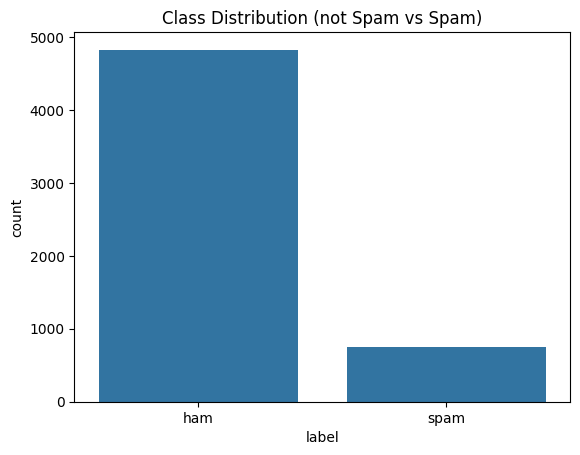

In [ ]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from imblearn.over_sampling import RandomOverSampler
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import learning_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import re
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

STOPWORDS = set(stopwords.words("english"))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


df = pd.read_csv("data/spam.csv", encoding="latin-1")  # path to dataset
df = df[['v1', 'v2']]
df.columns = ['label', 'message']

sns.countplot(x=df['label'])
plt.title("Class Distribution (not Spam vs Spam)")
plt.show()


In [ ]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z]", " ", text)  #keeps only letters
    text = " ".join([word for word in text.split() if word not in STOPWORDS])
    return text

df['cleaned'] = df['message'].apply(clean_text)

X_train, X_test, y_train, y_test = train_test_split(
    df['cleaned'], df['label'].map({'ham':0, 'spam':1}),
    test_size=0.2,
    random_state=42,
    stratify=df['label'].map({'ham':0, 'spam':1})#keeps ratio same
)

tfidf = TfidfVectorizer(max_features=3000, ngram_range=(1,2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec  = tfidf.transform(X_test)

X_train_vec.shape, X_test_vec.shape

((4457, 3000), (1115, 3000))

In [ ]:
def evaluate(model_name, y_true, y_pred):
    print(f"\n==== {model_name} ====")
    print(classification_report(y_true, y_pred, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    print("Confusion Matrix:\n", cm)
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))


def plot_learning_curve(ax, model, X, y, title, scoring="f1"):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X, y, cv=cv, scoring=scoring,
        train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1, error_score=np.nan
    )

    train_mean = np.nanmean(train_scores, axis=1)
    val_mean   = np.nanmean(val_scores, axis=1)

    ax.plot(train_sizes, train_mean, 'o-', color="blue", label="Train")
    ax.plot(train_sizes, val_mean, 'o-', color="green", label="Validation")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Train Size")
    ax.set_ylabel(scoring.upper())
    ax.grid(True)
    ax.legend(fontsize=6)

    #Fix y-axis scale
    ax.set_ylim(0.0, 1.0)
    ax.set_yticks(np.linspace(0.0, 1.0, 6))



In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

#function to evaluate return metrics in a row for a table
def evaluate_to_dict(model_name, strategy, stratified, y_true, y_pred):
    return {
        "Model": model_name,
        "Strategy": strategy,
        "Stratified": stratified,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Precision": round(precision_score(y_true, y_pred), 4),
        "Recall": round(recall_score(y_true, y_pred), 4),
        "F1": round(f1_score(y_true, y_pred), 4),
    }

results_table = []

#Baseline
nb = MultinomialNB()
nb.fit(X_train_vec, y_train)
y_pred_nb = nb.predict(X_test_vec)
results_table.append(evaluate_to_dict("Naive Bayes", "Baseline", True, y_test, y_pred_nb))

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_vec, y_train)
y_pred_lr = lr.predict(X_test_vec)
results_table.append(evaluate_to_dict("Logistic Regression", "Baseline", True, y_test, y_pred_lr))

svm = LinearSVC()
svm.fit(X_train_vec, y_train)
y_pred_svm = svm.predict(X_test_vec)
results_table.append(evaluate_to_dict("Linear SVM", "Baseline", True, y_test, y_pred_svm))


#Class Weight
lr_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_bal.fit(X_train_vec, y_train)
y_pred_lr_bal = lr_bal.predict(X_test_vec)
results_table.append(evaluate_to_dict("Logistic Regression", "Class Weight", True, y_test, y_pred_lr_bal))

svm_bal = LinearSVC(class_weight="balanced")
svm_bal.fit(X_train_vec, y_train)
y_pred_svm_bal = svm_bal.predict(X_test_vec)
results_table.append(evaluate_to_dict("Linear SVM", "Class Weight", True, y_test, y_pred_svm_bal))


#Oversampled
ros = RandomOverSampler(random_state=42)
X_train_over, y_train_over = ros.fit_resample(X_train_vec, y_train)

nb_over = MultinomialNB()
nb_over.fit(X_train_over, y_train_over)
y_pred_nb_over = nb_over.predict(X_test_vec)
results_table.append(evaluate_to_dict("Naive Bayes", "Oversampled", True, y_test, y_pred_nb_over))

lr_over = LogisticRegression(max_iter=1000)
lr_over.fit(X_train_over, y_train_over)
y_pred_lr_over = lr_over.predict(X_test_vec)
results_table.append(evaluate_to_dict("Logistic Regression", "Oversampled", True, y_test, y_pred_lr_over))

svm_over = LinearSVC()
svm_over.fit(X_train_over, y_train_over)
y_pred_svm_over = svm_over.predict(X_test_vec)
results_table.append(evaluate_to_dict("Linear SVM", "Oversampled", True, y_test, y_pred_svm_over))

results_df = pd.DataFrame(results_table)
results_df


,Model,Strategy,Stratified,Accuracy,Precision,Recall,F1
0,Naive Bayes,Baseline,True,0.9776,0.9921,0.8389,0.9091
1,Logistic Regression,Baseline,True,0.9731,0.9837,0.8121,0.8897
2,Linear SVM,Baseline,True,0.9857,1.0000,0.8926,0.9433
3,Logistic Regression,Class Weight,True,0.9758,0.9013,0.9195,0.9103
4,Linear SVM,Class Weight,True,0.9865,0.9786,0.9195,0.9481
5,Naive Bayes,Oversampled,True,0.9713,0.8634,0.9329,0.8968
6,Logistic Regression,Oversampled,True,0.9785,0.9195,0.9195,0.9195
7,Linear SVM,Oversampled,True,0.9874,0.9856,0.9195,0.9514


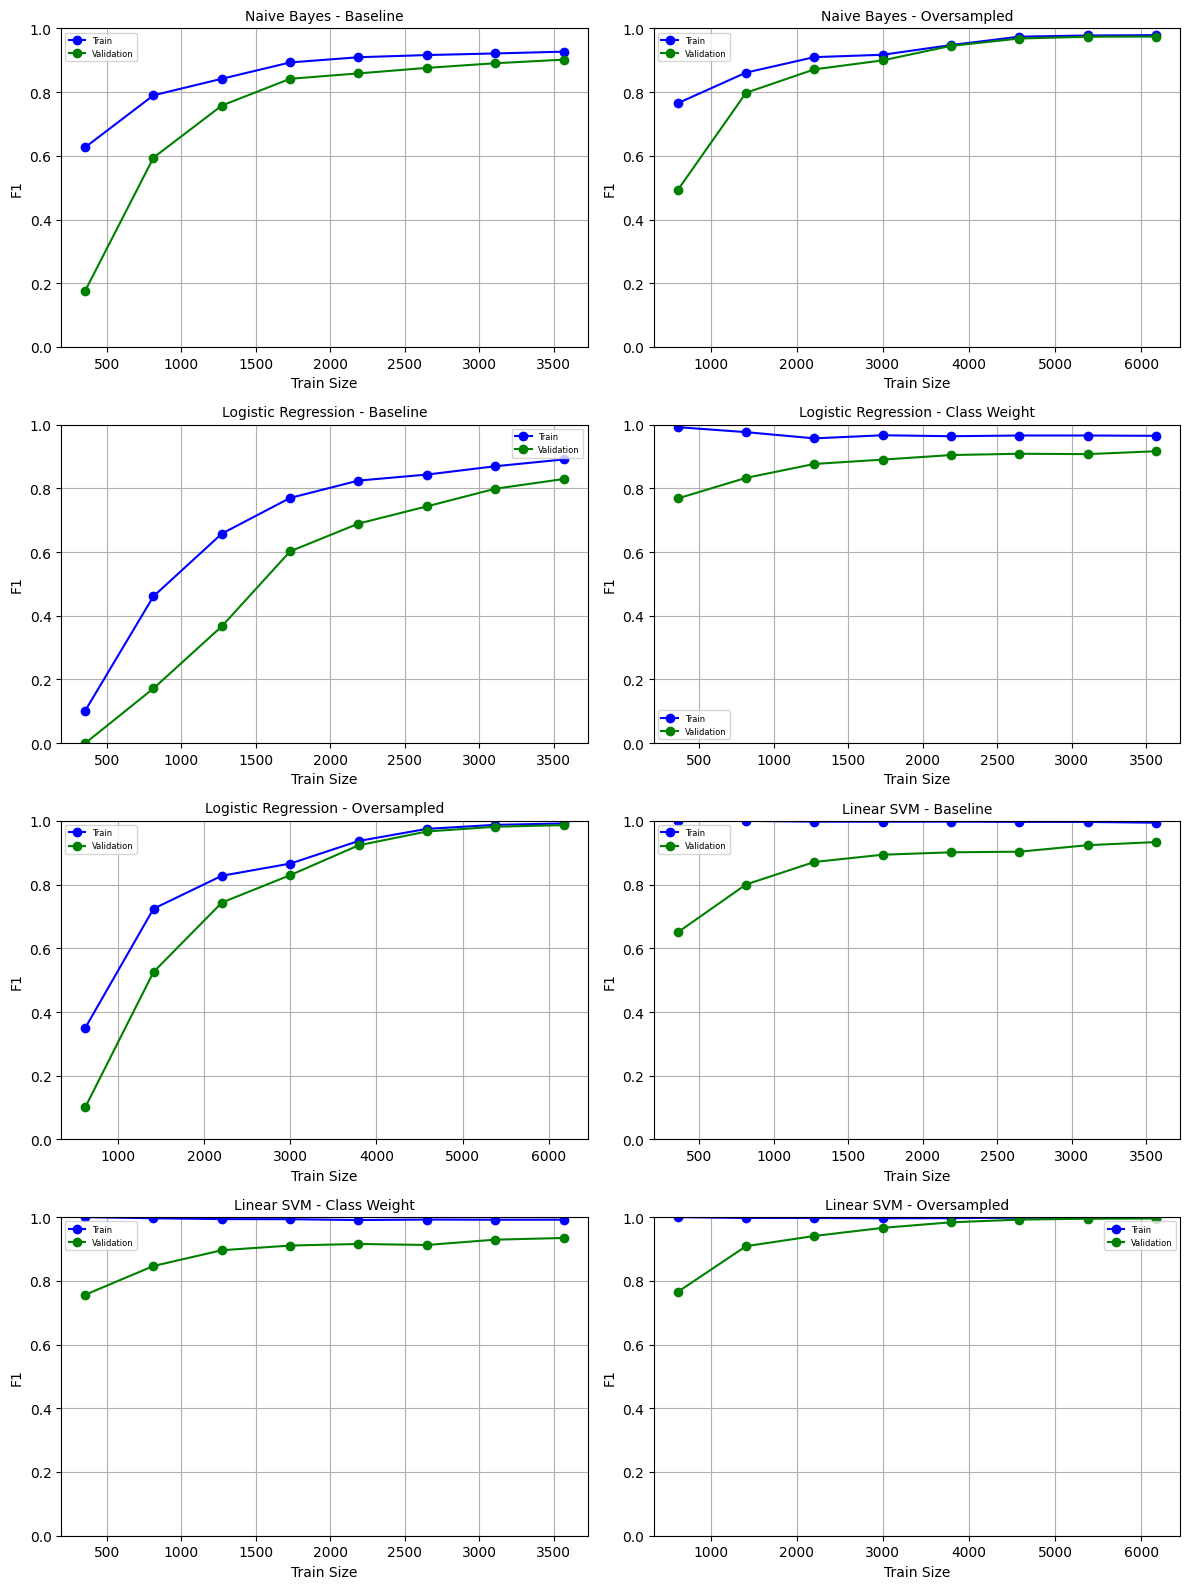

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(12, 16))
axes = axes.ravel()

# Baseline
plot_learning_curve(axes[0], MultinomialNB(), X_train_vec, y_train, "Naive Bayes - Baseline")
plot_learning_curve(axes[2], LogisticRegression(max_iter=1000), X_train_vec, y_train, "Logistic Regression - Baseline")
plot_learning_curve(axes[5], LinearSVC(), X_train_vec, y_train, "Linear SVM - Baseline")

#Class Weight.
plot_learning_curve(axes[3], LogisticRegression(max_iter=1000, class_weight="balanced"),
                    X_train_vec, y_train, "Logistic Regression - Class Weight")
plot_learning_curve(axes[6], LinearSVC(class_weight="balanced"),
                    X_train_vec, y_train, "Linear SVM - Class Weight")

# Oversampled
ros = RandomOverSampler(random_state=42)
X_train_over, y_train_over = ros.fit_resample(X_train_vec, y_train)

plot_learning_curve(axes[1], MultinomialNB(), X_train_over, y_train_over, "Naive Bayes - Oversampled")
plot_learning_curve(axes[4], LogisticRegression(max_iter=1000), X_train_over, y_train_over, "Logistic Regression - Oversampled")
plot_learning_curve(axes[7], LinearSVC(), X_train_over, y_train_over, "Linear SVM - Oversampled")

plt.tight_layout()
plt.show()

# GridSearchCV for hyper parameter tuning

In [ ]:
def run_grid(name, pipeline, param_grid, X_train, y_train, X_test, y_test, stratified=True):
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        verbose=0
    )
    grid.fit(X_train, y_train)
    best = grid.best_estimator_

    y_pred = best.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    row = {
        "Model": name.split(" | ")[0],
        "Strategy": name.split(" | ")[1],
        "Stratified": stratified,
        "Best Params": grid.best_params_,
        "CV F1 (mean)": round(grid.best_score_, 4),
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1": round(f1_score(y_test, y_pred), 4),
        "Spam Accuracy (Recall)": round(tp / (tp + fn), 4) if (tp + fn) else 0.0,
        "Ham Accuracy": round(tn / (tn + fp), 4) if (tn + fp) else 0.0,
    }
    return row, best


In [ ]:
results_tuned = []
best_models = {}

# MultinomialNB( Baseline)
pipe_nb = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", MultinomialNB())
])

grid_nb = {
    "tfidf__ngram_range": [(1,1), (1,2)],
    "tfidf__min_df": [1, 2, 5],
    "tfidf__max_features": [3000, 5000, 10000],
    "clf__alpha": [0.01, 0.1, 0.5, 1, 5],
}

row, best = run_grid("Naive Bayes | Baseline (tuned)", pipe_nb, grid_nb, X_train, y_train, X_test, y_test)
results_tuned.append(row); best_models["NB_baseline"] = best

#Logistic Regression(Baseline model)
pipe_lr = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(max_iter=2000))
])

grid_lr = {
    "tfidf__ngram_range": [(1,1), (1,2)],
    "tfidf__min_df": [1, 2, 5],
    "tfidf__max_features": [3000, 5000, 10000],
    "clf__C": [0.1, 1, 3, 10],
    "clf__penalty": ["l2"],
    "clf__solver": ["lbfgs"],
    "clf__class_weight": [None, "balanced"],
}

row, best = run_grid("Logistic Regression | Baseline (tuned)", pipe_lr, grid_lr, X_train, y_train, X_test, y_test)
results_tuned.append(row); best_models["LR_baseline"] = best

#Linear SVM (Baseline)
pipe_svm = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LinearSVC())
])

grid_svm = {
    "tfidf__ngram_range": [(1,1), (1,2)],
    "tfidf__min_df": [1, 2, 5],
    "tfidf__max_features": [3000, 5000, 10000],
    "clf__C": [0.1, 1, 3, 10],
    "clf__loss": ["hinge", "squared_hinge"],
    "clf__class_weight": [None, "balanced"],
}

row, best = run_grid("Linear SVM | Baseline (tuned)", pipe_svm, grid_svm, X_train, y_train, X_test, y_test)
results_tuned.append(row); best_models["SVM_baseline"] = best


In [ ]:
#MultinomialNB (Oversampled)
pipe_nb_over = ImbPipeline([
    ("tfidf", TfidfVectorizer()),
    ("sampler", RandomOverSampler(random_state=42)),
    ("clf", MultinomialNB())
])

grid_nb_over = {
    "tfidf__ngram_range": [(1,1), (1,2)],
    "tfidf__min_df": [1, 2, 5],
    "tfidf__max_features": [3000, 5000, 10000],
    "clf__alpha": [0.01, 0.1, 0.5, 1, 5],
}

row, best = run_grid("Naive Bayes | Oversampled (tuned)", pipe_nb_over, grid_nb_over, X_train, y_train, X_test, y_test)
results_tuned.append(row); best_models["NB_over"] = best

# Logistic Regression (Oversampled
pipe_lr_over = ImbPipeline([
    ("tfidf", TfidfVectorizer()),
    ("sampler", RandomOverSampler(random_state=42)),
    ("clf", LogisticRegression(max_iter=2000))
])

grid_lr_over = {
    "tfidf__ngram_range": [(1,1), (1,2)],
    "tfidf__min_df": [1, 2, 5],
    "tfidf__max_features": [3000, 5000, 10000],
    "clf__C": [0.1, 1, 3, 10],
    "clf__penalty": ["l2"],
    "clf__solver": ["lbfgs"],
}

row, best = run_grid("Logistic Regression | Oversampled (tuned)", pipe_lr_over, grid_lr_over, X_train, y_train, X_test, y_test)
results_tuned.append(row); best_models["LR_over"] = best

# Linear SVM (Oversampled)
pipe_svm_over = ImbPipeline([
    ("tfidf", TfidfVectorizer()),
    ("sampler", RandomOverSampler(random_state=42)),
    ("clf", LinearSVC())
])

grid_svm_over = {
    "tfidf__ngram_range": [(1,1), (1,2)],
    "tfidf__min_df": [1, 2, 5],
    "tfidf__max_features": [3000, 5000, 10000],
    "clf__C": [0.1, 1, 3, 10],
    "clf__loss": ["hinge", "squared_hinge"],
}

row, best = run_grid("Linear SVM | Oversampled (tuned)", pipe_svm_over, grid_svm_over, X_train, y_train, X_test, y_test)
results_tuned.append(row); best_models["SVM_over"] = best


# Comparing results

In [ ]:
results_tuned_df = pd.DataFrame(results_tuned)
#Make copies
base = results_df.copy()
tuned = results_tuned_df.copy()

#Normalize BASE (no tuning)
if "Best Params" not in base.columns:
    base["Best Params"] = None  # fill with null
if "CV F1 (mean)" not in base.columns:
    base["CV F1 (mean)"] = np.nan
# Spam Accuracy == Recall for positive class
if "Spam Accuracy (Recall)" not in base.columns:
    base["Spam Accuracy (Recall)"] = base["Recall"]

base_cols = [
    "Model", "Strategy", "Stratified",
    "Best Params", "CV F1 (mean)",
    "Accuracy", "Precision", "Recall", "F1",
    "Spam Accuracy (Recall)"
]
base = base.reindex(columns=base_cols)

#Normalize with tuning
if "Ham Accuracy" in tuned.columns:
    tuned = tuned.drop(columns=["Ham Accuracy"])

tuned = tuned.reindex(columns=base_cols)
combined = pd.concat([base, tuned], ignore_index=True)
combined = combined.sort_values(by=["F1", "Recall", "Precision"], ascending=False).reset_index(drop=True)

combined

,Model,Strategy,Stratified,Best Params,CV F1 (mean),Accuracy,Precision,Recall,F1,Spam Accuracy (Recall)
0,Linear SVM,Baseline (tuned),True,"{'clf__C': 3, 'clf__class_weight': 'balanced',...",0.9418,0.9883,1.0000,0.9128,0.9544,0.9128
1,Linear SVM,Oversampled,True,None,NaN,0.9874,0.9856,0.9195,0.9514,0.9195
2,Linear SVM,Oversampled (tuned),True,"{'clf__C': 3, 'clf__loss': 'squared_hinge', 't...",0.9425,0.9874,0.9927,0.9128,0.9510,0.9128
3,Linear SVM,Class Weight,True,None,NaN,0.9865,0.9786,0.9195,0.9481,0.9195
4,Naive Bayes,Baseline (tuned),True,"{'clf__alpha': 0.01, 'tfidf__max_features': 10...",0.9456,0.9857,0.9854,0.9060,0.9441,0.9060
5,Linear SVM,Baseline,True,None,NaN,0.9857,1.0000,0.8926,0.9433,0.8926
6,Logistic Regression,Oversampled (tuned),True,"{'clf__C': 10, 'clf__penalty': 'l2', 'clf__sol...",0.9373,0.9848,0.9714,0.9128,0.9412,0.9128
7,Logistic Regression,Baseline (tuned),True,"{'clf__C': 10, 'clf__class_weight': 'balanced'...",0.9383,0.9839,0.9580,0.9195,0.9384,0.9195
8,Logistic Regression,Oversampled,True,None,NaN,0.9785,0.9195,0.9195,0.9195,0.9195
9,Logistic Regression,Class Weight,True,None,NaN,0.9758,0.9013,0.9195,0.9103,0.9195


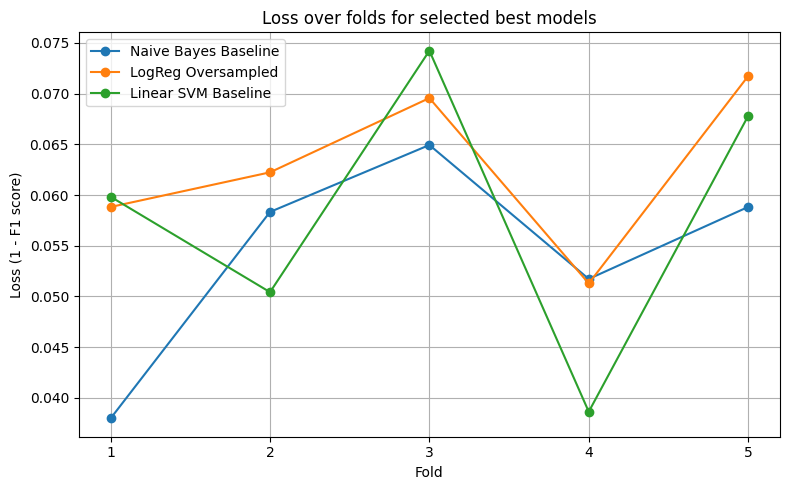

In [ ]:
from sklearn.model_selection import cross_val_score
import numpy as np
import matplotlib.pyplot as plt


models_to_plot = {
    "Naive Bayes Baseline": best_models["NB_baseline"],
    "LogReg Oversampled":   best_models["LR_over"],
    "Linear SVM Baseline":  best_models["SVM_baseline"],
}

plt.figure(figsize=(8, 5))

for name, model in models_to_plot.items():
    # 5-fold CV F1 scores
    f1_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1")
    losses = 1.0 - f1_scores

    folds = np.arange(1, len(losses) + 1)
    plt.plot(folds, losses, marker="o", linestyle="-", label=name)

plt.xlabel("Fold")
plt.ylabel("Loss (1 - F1 score)")
plt.title("Loss over folds for selected best models")
plt.xticks(folds)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd, numpy as np, ast, json
def _to_params_dict(x):
    if isinstance(x, dict):
        return x
    if x is None or (isinstance(x, float) and np.isnan(x)) or str(x).strip().lower() in {"none", ""}:
        return {}
    return ast.literal_eval(x)


def _pretty_params(x):
    return "Default (untuned)" if not x else json.dumps(x, indent=2, sort_keys=True)

sort_cols = ["F1", "Recall", "Precision"]
ordered = combined.sort_values(by=sort_cols, ascending=False)

of_interest = ["Linear SVM", "Naive Bayes", "Logistic Regression"]
best_per_model = (
    ordered[ordered["Model"].isin(of_interest)]
    .groupby("Model", as_index=False)
    .first()
    .copy()
)

best_per_model["Best Params (dict)"] = best_per_model["Best Params"].apply(_to_params_dict)
best_per_model["Best Params (pretty)"] = best_per_model["Best Params (dict)"].apply(_pretty_params)
cols = [
    "Model", "Strategy", "Stratified",
    "Best Params (pretty)",
    "CV F1 (mean)", "Accuracy", "Precision", "Recall", "F1", "Spam Accuracy (Recall)"
]
best_view = best_per_model.reindex(columns=cols)
print(best_view.to_string(index=False))


              Model            Strategy  Stratified                                                                                                                                                                             Best Params (pretty)  CV F1 (mean)  Accuracy  Precision  Recall     F1  Spam Accuracy (Recall)
         Linear SVM    Baseline (tuned)        True {\n  "clf__C": 3,\n  "clf__class_weight": "balanced",\n  "clf__loss": "squared_hinge",\n  "tfidf__max_features": 10000,\n  "tfidf__min_df": 1,\n  "tfidf__ngram_range": [\n    1,\n    2\n  ]\n}        0.9418    0.9883     1.0000  0.9128 0.9544                  0.9128
Logistic Regression Oversampled (tuned)        True                  {\n  "clf__C": 10,\n  "clf__penalty": "l2",\n  "clf__solver": "lbfgs",\n  "tfidf__max_features": 5000,\n  "tfidf__min_df": 1,\n  "tfidf__ngram_range": [\n    1,\n    2\n  ]\n}        0.9373    0.9848     0.9714  0.9128 0.9412                  0.9128
        Naive Bayes    Baseline (tuned)    

In [ ]:
# Save best models
from pathlib import Path
import joblib
# "SVM_baseline", "LR_over", "NB_baseline"

Path("models").mkdir(parents=True, exist_ok=True)

to_save = {
    "linear_svm_baseline.joblib": best_models["SVM_baseline"],
    "logreg_oversampled.joblib": best_models["LR_over"],
    "naive_bayes_baseline.joblib": best_models["NB_baseline"],
}

for filename, estimator in to_save.items():
    joblib.dump(estimator, f"models/{filename}", compress=3)


In [ ]:
from pathlib import Path
import joblib
import numpy as np
from sklearn.metrics import f1_score

models_dir = Path("models")
svm = joblib.load(models_dir / "linear_svm_baseline.joblib")
lr  = joblib.load(models_dir / "logreg_oversampled.joblib")
nb  = joblib.load(models_dir / "naive_bayes_baseline.joblib")

MODELS = [svm, lr, nb]
NAMES  = ["SVM", "LR", "NB"]


raw_weights = np.array([0.9418, 0.9373, 0.9456], dtype=float)
WEIGHTS = (raw_weights / raw_weights.sum()).tolist()  # normalize to sum=1

def weighted_hard_vote(models, weights, X):

    preds = [m.predict(X) for m in models]
    preds = np.stack(preds, axis=1)
    signed = preds * 2 - 1
    score = np.dot(signed, np.asarray(weights))
    return (score > 0).astype(int)


if __name__ == "__main__":
    try:
        y_pred = weighted_hard_vote(MODELS, WEIGHTS, X_test)
        print("Ensemble F1:", round(f1_score(y_test, y_pred), 4))
    except Exception:
        pass


Ensemble F1: 0.9544


# Test with our text

In [ ]:
# Build pipeline with the chosen best params
best_svm = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1,2), min_df=1, max_features=5000)),
    ("clf", LinearSVC(C=3, class_weight="balanced"))
])

# Train on full training data
best_svm.fit(X_train, y_train)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
                ('clf', LinearSVC(C=3, class_weight='balanced'))])

In [ ]:
# Get trained steps and wights from best model
vectorizer = best_svm.named_steps["tfidf"]
clf = best_svm.named_steps["clf"]

feature_names = np.array(vectorizer.get_feature_names_out())

coefs = clf.coef_[0]

# Top spam indicators
top_spam_idx = np.argsort(coefs)[-20:][::-1]
top_spam_words = feature_names[top_spam_idx]
top_spam_weights = coefs[top_spam_idx]

# Top ham indicators
top_ham_idx = np.argsort(coefs)[:20]
top_ham_words = feature_names[top_ham_idx]
top_ham_weights = coefs[top_ham_idx]


In [ ]:
spam_df = pd.DataFrame({"Word": top_spam_words, "Weight": top_spam_weights})
ham_df = pd.DataFrame({"Word": top_ham_words, "Weight": top_ham_weights})

print("Top Spam Words")
display(spam_df)

print("Top Ham Words")
display(ham_df)


Top Spam Words


,Word,Weight
0,mobile,2.426892
1,txt,2.299055
2,uk,2.242633
3,claim,2.195342
4,services,1.924275
5,tf,1.904393
6,com,1.879211
7,choose,1.855550
8,www,1.810847
9,order,1.810388


Top Ham Words


,Word,Weight
0,remember,-1.265237
1,told,-1.252835
2,yup,-1.152683
3,mail,-1.147917
4,home,-1.007574
5,liked,-0.952646
6,babe lost,-0.946899
7,sleep,-0.936136
8,alright,-0.895312
9,sorry,-0.871658


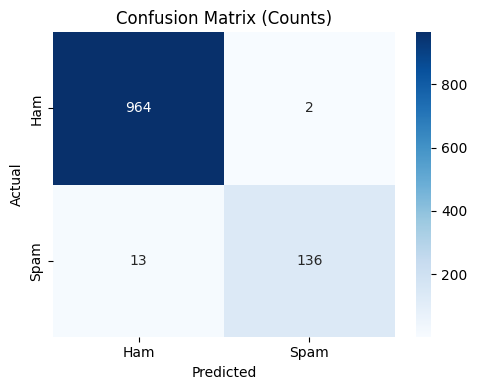

In [ ]:
y_pred = best_svm.predict(X_test)

# Confusion matrix 0=ham, 1=spam
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Ham","Spam"], yticklabels=["Ham","Spam"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Counts)")
plt.tight_layout()
plt.show()


In [ ]:
spam_examples = df[df["label"] == "spam"].sample(10, random_state=42)

for i, msg in enumerate(spam_examples["message"], 1):
    print(f"{i}. {msg}\n")

1. Summers finally here! Fancy a chat or flirt with sexy singles in yr area? To get MATCHED up just reply SUMMER now. Free 2 Join. OptOut txt STOP Help08714742804

2. This is the 2nd time we have tried 2 contact u. U have won the 750 Pound prize. 2 claim is easy, call 08718726970 NOW! Only 10p per min. BT-national-rate 

3. Get ur 1st RINGTONE FREE NOW! Reply to this msg with TONE. Gr8 TOP 20 tones to your phone every week just å£1.50 per wk 2 opt out send STOP 08452810071 16

4. Ur cash-balance is currently 500 pounds - to maximize ur cash-in now send GO to 86688 only 150p/msg. CC: 08718720201 PO BOX 114/14 TCR/W1

5. Last Chance! Claim ur å£150 worth of discount vouchers today! Text SHOP to 85023 now! SavaMob, offers mobile! T Cs SavaMob POBOX84, M263UZ. å£3.00 Sub. 16

6. You can stop further club tones by replying \STOP MIX\" See my-tone.com/enjoy. html for terms. Club tones cost GBP4.50/week. MFL

7. For ur chance to win a å£250 cash every wk TXT: ACTION to 80608. T's&C's www.movi


Original Test Split
Accuracy:           0.9883
Precision (spam=1): 1.0000
Recall    (spam=1): 0.9128
F1        (spam=1): 0.9544
F1 (macro):         0.9739
F1 (weighted):      0.9881
Balanced accuracy:  0.9564
Specificity (TNR):  1.0000
MCC:                0.9490

Classification report:
               precision    recall  f1-score   support

         HAM       0.99      1.00      0.99       966
        SPAM       1.00      0.91      0.95       149

    accuracy                           0.99      1115
   macro avg       0.99      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



<Figure size 640x480 with 0 Axes>

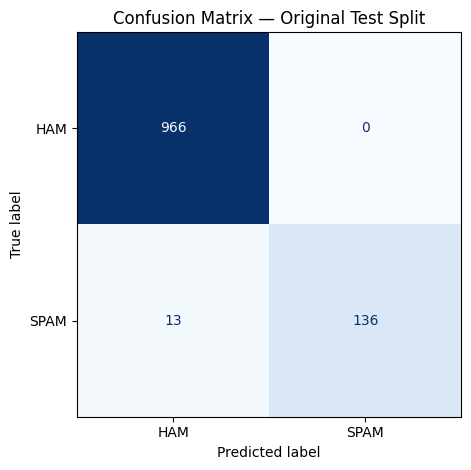

In [ ]:
# Evaluate ensemble
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    matthews_corrcoef, balanced_accuracy_score, classification_report
)



#metrics
def print_full_metrics(y_true, y_pred, title="Test split metrics"):
    cm = confusion_matrix(y_true, y_pred, labels=[0,1])
    tn, fp, fn, tp = cm.ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    print(f"\n{title}")
    print(f"Accuracy:           {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision (spam=1): {precision_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"Recall    (spam=1): {recall_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"F1        (spam=1): {f1_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"F1 (macro):         {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
    print(f"F1 (weighted):      {f1_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")
    print(f"Balanced accuracy:  {balanced_accuracy_score(y_true, y_pred):.4f}")
    print(f"Specificity (TNR):  {specificity:.4f}")
    print(f"MCC:                {matthews_corrcoef(y_true, y_pred):.4f}")
    print("\nClassification report:\n", classification_report(y_true, y_pred, target_names=["HAM","SPAM"], zero_division=0))

    disp = ConfusionMatrixDisplay(cm, display_labels=["HAM","SPAM"])
    plt.figure()
    disp.plot(values_format="d", cmap="Blues", colorbar=False)
    plt.title(f"Confusion Matrix — {title}")
    plt.tight_layout()
    plt.show()

#evaluation
def eval_test_split(X_test, y_test, title="Original Test Split"):
    y_pred = weighted_hard_vote(MODELS, WEIGHTS, X_test)
    print_full_metrics(y_test, y_pred, title=title)


eval_test_split(X_test, y_test)

